# Karnataka electoral roll, 2026 SIR

In [1]:
import duckdb

BASE = "https://data.sir.diagramchasing.fun/releases/2026-10-28-statewide.3/"
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")

for t in ["summary", "parts", "constituencies", "population_age", "roll_changes", "data_quality"]:
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM read_parquet('{BASE}{t}.parquet')")

q = lambda sql: con.sql(sql).df()

## Statewide

In [2]:
q("""
SELECT observed_records::BIGINT AS entries,
       printed_net_electors::BIGINT AS eci_net_electors,
       additions::BIGINT AS additions,
       deletions::BIGINT AS deletions,
       modifications::BIGINT AS modifications
FROM summary
WHERE level = 'state'
""")

,entries,eci_net_electors,additions,deletions,modifications
0,45643915,45212232,1007687,188330,907529


In [3]:
q("""
SELECT level, count(*) AS rows
FROM summary
GROUP BY level
""")

,level,rows
0,constituency,224
1,state,1
2,district,34
3,part,60923


## Deletions

In [4]:
q("""
SELECT deletion_code,
       sum(records)::BIGINT AS entries,
       round(100.0 * sum(records) / sum(sum(records)) OVER (), 1) AS pct
FROM roll_changes
WHERE status = 'deletion'
GROUP BY 1
ORDER BY 2 DESC
""")

,deletion_code,entries,pct
0,S-Shifted,124490,66.1
1,Q-Disqualified,61915,32.9
2,E-Expired,1158,0.6
3,R-Repeated,765,0.4
4,M-Missing,2,0.0


In [5]:
q("""
SELECT ac, constituency, district,
       observed_records::BIGINT AS entries,
       deletions::BIGINT AS deletions,
       deletions_per_1000
FROM summary
WHERE level = 'constituency'
ORDER BY deletions_per_1000 DESC
LIMIT 10
""")

,ac,constituency,district,entries,deletions,deletions_per_1000
0,175,Bommanahalli,B.B.M.P(SOUTH),230243,5900,26.30
1,161,C.V. RamannNagar,B.B.M.P(NORTH),140540,2917,21.20
2,173,Jayanagar,B.B.M.P(SOUTH),131859,2561,19.81
3,158,Hebbal,B.B.M.P(NORTH),179214,3197,18.16
4,151,K.R. Pura,B.B.M.P(NORTH),319701,5622,17.90
5,167,Vijayanagar,B.B.M.P(SOUTH),163307,2727,16.98
6,157,Malleshwaram,B.B.M.P(NORTH),127516,1978,15.76
7,174,Mahadevapura,BANGALORE URBAN,417032,6357,15.48
8,166,Govindarajanagar,B.B.M.P(SOUTH),164186,2472,15.29
9,146,Kolar Gold Field,KOLAR,166942,2316,14.07


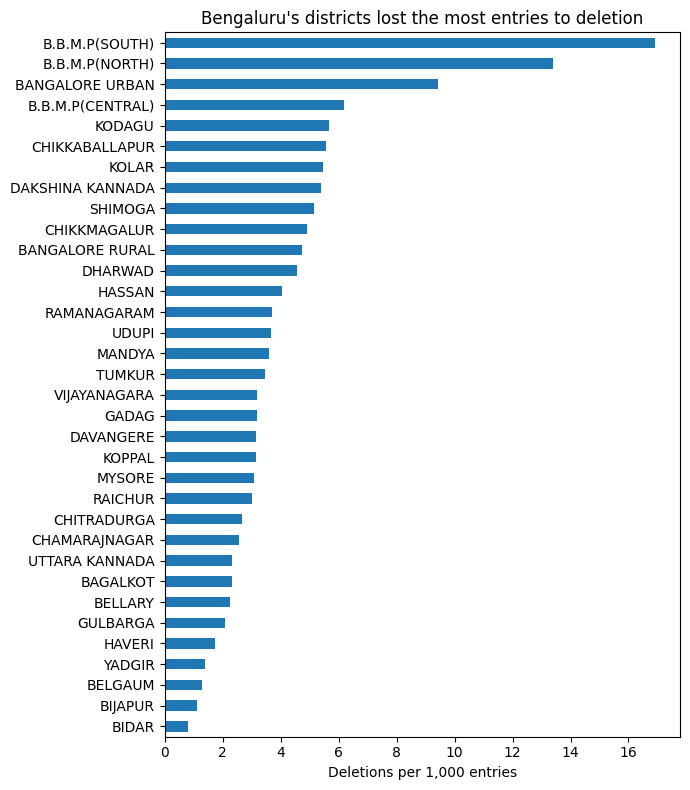

In [6]:
import matplotlib.pyplot as plt

by_district = q("""
SELECT district, deletions_per_1000
FROM summary
WHERE level = 'district'
ORDER BY deletions_per_1000
""")

ax = by_district.plot.barh(x="district", y="deletions_per_1000", legend=False, figsize=(7, 8))
ax.set_xlabel("Deletions per 1,000 entries")
ax.set_ylabel("")
ax.set_title("Bengaluru's districts lost the most entries to deletion")
plt.tight_layout()

## Entries in one constituency, joined to their polling station

In [7]:
AC = 200

con.execute(f"CREATE VIEW electors AS SELECT * FROM read_parquet('{BASE}electors/electors-ac-{AC:03d}.parquet')")

q("""
SELECT e.part, p.part_name,
       count(*) AS entries,
       p.printed_net_electors AS eci_net_electors,
       p.reconciliation
FROM electors e
JOIN parts p ON p.ac = e.ac AND p.part = e.part
GROUP BY ALL
ORDER BY entries DESC
LIMIT 5
""")

,part,part_name,entries,eci_net_electors,reconciliation
0,74,Dakshina Kannada Zilla Panachayath Unnathik...,1210,1205,matched
1,102,Dakshina Kannada Zilla Panchayath Higher ...,1203,1188,matched
2,171,Dakshina Kannada Zilla Panchayath Higher P...,1198,1191,matched
3,50,"AIDED H P SCHOOL, KOKRADY",1194,1190,matched
4,114,Shree Darmasthala Manjunatheswara Aided Hi...,1191,1186,mismatch


In [8]:
q("""
SELECT status, gender, count(*) AS entries, round(avg(age), 1) AS mean_age
FROM electors
GROUP BY ALL
ORDER BY status, entries DESC
""")

,status,gender,entries,mean_age
0,addition,female,3192,28.3
1,addition,male,2464,27.1
2,base,female,105406,45.8
3,base,male,104292,44.5
4,deletion,female,626,38.2
5,deletion,unknown,437,39.8
6,deletion,male,312,44.4
7,modification,male,3582,46.4
8,modification,female,3317,47.8


## Age by district

In [9]:
# sum counts, then divide: averaging per-constituency percentages would weight constituencies equally
q("""
SELECT c.district,
       sum(a.records) FILTER (WHERE a.age BETWEEN 18 AND 24)::BIGINT AS aged_18_24,
       sum(a.records) FILTER (WHERE a.age IS NOT NULL)::BIGINT AS known_age,
       round(100.0 * sum(a.records) FILTER (WHERE a.age BETWEEN 18 AND 24)
             / sum(a.records) FILTER (WHERE a.age IS NOT NULL), 1) AS pct_18_24
FROM population_age a
JOIN constituencies c ON c.ac = a.ac
WHERE a.status <> 'deletion'
GROUP BY 1
ORDER BY pct_18_24 DESC
LIMIT 10
""")

,district,aged_18_24,known_age,pct_18_24
0,BELLARY,139623,1020108,13.7
1,KOPPAL,135541,1058995,12.8
2,VIJAYANAGARA,124372,1008229,12.3
3,BAGALKOT,169189,1412880,12.0
4,YADGIR,102201,887032,11.5
5,RAICHUR,162715,1424750,11.4
6,KOLAR,128355,1139222,11.3
7,BIDAR,139402,1246531,11.2
8,CHITRADURGA,145863,1316796,11.1
9,GULBARGA,204305,1893702,10.8


## Quality

In [10]:
q("""
SELECT ac, constituency, expected_parts,
       mismatched_parts::INT AS mismatched_parts,
       flagged_pct, mean_confidence
FROM data_quality
ORDER BY mismatched_parts DESC
LIMIT 10
""")

,ac,constituency,expected_parts,mismatched_parts,flagged_pct,mean_confidence
0,175,Bommanahalli,390,68,0.609,0.9808
1,174,Mahadevapura,533,64,1.141,0.9787
2,151,K.R. Pura,509,62,0.363,0.9749
3,200,Belthangady,268,56,0.324,0.9999
4,137,Pavagada,251,47,0.438,0.9780
5,158,Hebbal,285,42,0.407,0.9756
6,161,C.V. RamannNagar,244,41,0.481,0.9765
7,27,Devara Hippargi,256,39,2.263,0.9823
8,153,Yeshwanthapura,553,37,0.266,0.9750
9,154,Rajarajeshwarinagar,437,33,0.355,0.9763
